# Classificação Iris com TensorFlow
Gabriel das Chagas Silva | Anhanguera | Engenharia de Software

Disciplina: Linguagem de Programação. Notebook compatível com Google Colab. Resultados desta entrega executados localmente em Python em 13/10/2026.

No Colab: Arquivo > Fazer upload de notebook; depois Ambiente de execução > Executar tudo. Se faltar uma biblioteca, instale matplotlib, seaborn, pandas, scikit-learn e tensorflow com pip.

## Bibliotecas e carregamento do Iris

In [1]:
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)
iris = load_iris()
X, y = iris.data, iris.target
df = pd.DataFrame(X, columns=iris.feature_names)
df['especie'] = [iris.target_names[i] for i in y]
print('DADOS IRIS:', X.shape, '| classes:', iris.target_names.tolist())
print(df.head().to_string(index=False))

DADOS IRIS: (150, 4) | classes: ['setosa', 'versicolor', 'virginica']
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) especie
               5.1               3.5                1.4               0.2  setosa
               4.9               3.0                1.4               0.2  setosa
               4.7               3.2                1.3               0.2  setosa
               4.6               3.1                1.5               0.2  setosa
               5.0               3.6                1.4               0.2  setosa


## Divisão estratificada e padronização sem vazamento de dados

In [2]:
X_treino_total, X_teste, y_treino_total, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X_treino_total, y_treino_total, test_size=0.20, random_state=42,
    stratify=y_treino_total)
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino).astype('float32')
X_validacao_pad = scaler.transform(X_validacao).astype('float32')
X_teste_pad = scaler.transform(X_teste).astype('float32')
print(f'Treino: {len(X_treino)}; validação: {len(X_validacao)}; teste: {len(X_teste)}')

Treino: 96; validação: 24; teste: 30


## Construção e treinamento da rede neural TensorFlow

In [3]:
modelo = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax'),
])
modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
               loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo.summary()
parada = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)
historico = modelo.fit(
    X_treino_pad, y_treino, validation_data=(X_validacao_pad, y_validacao),
    epochs=150, batch_size=16, verbose=0, callbacks=[parada])
print('Épocas executadas:', len(historico.history['loss']))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

Épocas executadas: 79


## Avaliação única no conjunto de teste reservado

Perda no teste: 0.1020; acurácia: 96.67%
Matriz de confusão (linhas reais, colunas previstas):
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



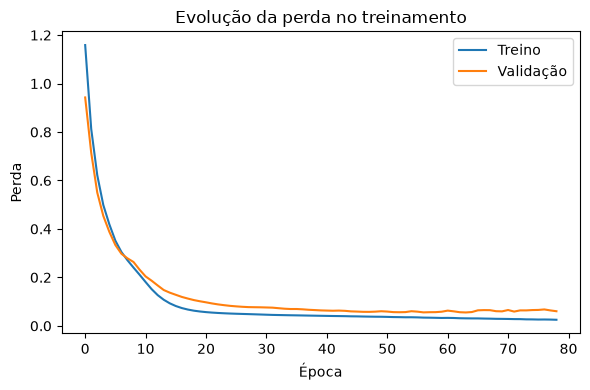

In [4]:
perda, acuracia = modelo.evaluate(X_teste_pad, y_teste, verbose=0)
probabilidades = modelo.predict(X_teste_pad, verbose=0)
predicoes = probabilidades.argmax(axis=1)
matriz = confusion_matrix(y_teste, predicoes)
print(f'Perda no teste: {perda:.4f}; acurácia: {acuracia:.2%}')
print('Matriz de confusão (linhas reais, colunas previstas):\n', matriz)
print(classification_report(y_teste, predicoes,
      target_names=iris.target_names, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(historico.history['loss'], label='Treino')
ax.plot(historico.history['val_loss'], label='Validação')
ax.set(title='Evolução da perda no treinamento', xlabel='Época', ylabel='Perda')
ax.legend()
fig.tight_layout()
fig.savefig('treinamento_iris.png', dpi=180)
plt.show()

## Previsões de três novas entradas demonstrativas

In [5]:
novas_flores = np.array([[5.1, 3.5, 1.4, 0.2],
                        [6.0, 2.9, 4.5, 1.5],
                        [6.5, 3.0, 5.8, 2.2]])
probs = modelo.predict(scaler.transform(novas_flores).astype('float32'), verbose=0)
previsoes_novas = []
for medidas, p in zip(novas_flores, probs):
    especie = str(iris.target_names[int(p.argmax())])
    previsoes_novas.append(especie)
    print(f'Medidas {medidas.tolist()} -> {especie}; probabilidades {p.round(4).tolist()}')
assert len(y_teste) == 30 and matriz.sum() == 30
assert np.isfinite(probabilidades).all()
assert np.allclose(probabilidades.sum(axis=1), 1, atol=1e-5)
assert np.allclose(X_treino_pad.mean(axis=0), 0, atol=1e-5)
print('TESTES: divisão, padronização e probabilidades conferidas.')
modelo.save('modelo_iris.keras')
with open('resultados.json', 'w', encoding='utf-8') as arquivo:
    json.dump({'treino': len(y_treino), 'validacao': len(y_validacao), 'teste': len(y_teste),
               'epocas': len(historico.history['loss']), 'perda': float(perda),
               'acuracia': float(acuracia), 'matriz': matriz.tolist(),
               'previsoes': previsoes_novas}, arquivo, indent=2, ensure_ascii=False)

Medidas [5.1, 3.5, 1.4, 0.2] -> setosa; probabilidades [0.9998999834060669, 9.999999747378752e-05, 0.0]
Medidas [6.0, 2.9, 4.5, 1.5] -> versicolor; probabilidades [9.999999747378752e-05, 0.9934999942779541, 0.006399999838322401]
Medidas [6.5, 3.0, 5.8, 2.2] -> virginica; probabilidades [0.0, 0.0, 1.0]
TESTES: divisão, padronização e probabilidades conferidas.
